# Process mutation data from the LTEE

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

from Bio import SeqIO

In [2]:
data_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/data"
out_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/out"
fig_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/figures"

## Load data from LTEE

In [3]:
#Substitutions
data_substitutions = pd.read_pickle(data_path + "/all_muts.pkl")

#Consensus has a T at position 3085, but mutations from C are recorded instead of mutations from T - change
data_3085 = data_substitutions[data_substitutions['pos']==3085]
data_3085.sort_values(by=['passage','line'])

#Replace rows from C at position 3085 with rows from T
pds = []
for line in range(13,21):
    for passage in range(10,520,10):
        rows = data_3085[(data_3085['line'] == str(line)) & (data_3085['passage'] == passage)].copy()
        if len(rows) == 0:
            rows.loc[0] = [3085,'C',1,np.nan,np.nan,str(line),passage]
        else:
            if rows['fraction'].sum() < 0.999:
                new_row = rows.iloc[0].copy()
                new_row['new'] = 'C'
                new_row['fraction'] = 1 - rows['fraction'].sum()
                new_row['reads'] = (new_row['coverage'] - rows['reads'].sum()).astype(int)
                rows.loc[len(rows)] = new_row
                rows['reads'] = rows['reads'].astype(int)
            idx = rows[rows['new']=='T'].index
            rows = rows.drop(idx)
            
        pds.append(rows)
data_3085_new = pd.concat(pds)

#Put new rows into dataframe
data_substitutions = data_substitutions[~(data_substitutions['pos']==3085)]
data_substitutions = pd.concat([data_substitutions,data_3085_new]).reset_index(drop=True)
data_substitutions['type'] = 'substitution'

#Insertions ('pos' is the position of the insertion and 'new' is 'i:'+inserted sequence)
data_insertions = pd.read_pickle(data_path + "/all_ins.pkl")
data_insertions['inserted'] = 'i:' + data_insertions['inserted']
data_insertions = data_insertions.rename(columns={'inserted':'new'})
data_insertions['type'] = 'insertion'

#Deletions ('pos' is the start of the deletion, and 'new' is 'd:'+length of the deletion)
data_deletions = pd.read_pickle(data_path + "/all_dels.pkl")
data_deletions['end'] = data_deletions['end'] - data_deletions['start']
data_deletions['end'] = 'd:' + data_deletions['end'].astype(str)
data_deletions = data_deletions.rename(columns={'start':'pos','end':'new'})
data_deletions['type'] = 'deletion'

#Combine substitutions, insertions, deletions
data = pd.concat([data_substitutions,data_insertions,data_deletions])

#Switch lines 15 and 16 after passage 360 as in experiment
data_new = data.copy()
data_new.loc[np.logical_and(data['line']=='15',data['passage']>360),'line'] = '16'
data_new.loc[np.logical_and(data['line']=='16',data['passage']>360),'line'] = '15'
data = data_new

#Save mutation data
data.to_pickle(out_path + f'/mutation_data.pkl')

data

,pos,new,fraction,reads,coverage,line,passage,type
0,6806,A,1.000000,5441.0,5441.0,14,420,substitution
1,8919,A,1.000000,5464.0,5464.0,17,500,substitution
2,3757,C,1.000000,1986.0,1986.0,18,500,substitution
3,7117,T,1.000000,6921.0,6921.0,19,490,substitution
4,8408,A,1.000000,5554.0,5554.0,17,500,substitution
...,...,...,...,...,...,...,...,...
459368,1258,d:2,0.000006,1.0,160853.0,19,440,deletion
459245,1267,d:2,0.000006,1.0,160853.0,19,440,deletion
459376,1260,d:1,0.000006,1.0,160853.0,19,440,deletion
459382,1264,d:2,0.000006,1.0,160853.0,19,440,deletion


In [4]:
#Substitution mutation information
mutations_data = pd.read_pickle(data_path + "/mutation_types.pkl")
mutations_data['new'] = mutations_data['new'].str[1] #remove extra space
mutations_data.head()

,pos,new,gene,muttype,details
0,47,A,-,Non-coding,-
1,48,A,-,Non-coding,-
2,49,A,-,Non-coding,-
3,51,C,-,Non-coding,-
4,53,C,-,Non-coding,-


In [5]:
#Gene positions
gene_positions = pd.read_csv(data_path + '/genes.csv')
gene_positions.head()

,start,end,genename
0,789,2289,Gag
1,2084,5093,Pol
2,5040,5616,Vif
3,5558,5846,Vpr
4,5830,6045,Tat


In [6]:
#Consensus (position starts at 0)
for record in SeqIO.parse(data_path + "/ancestor_consensus.fasta", "fasta"):
    consensus = record.seq

print(f'Length = {len(consensus)}')
print(f'Sequence = {consensus}')

Length = 14825
Sequence = TGGAAGGGCTAATTTGGTCCCAAAAAAGACAAGATATCCTTGATCTGTGGATCTACCACACACAAGGCTACTTCCCTGATTGGCAGAACTACACACCAGGGCCAGGGATCAGATATCCACTGACCTTTGGATGGTGCTTCAAGTTAGTACCAGTTGAACCAGAGCAAGTAGAAGAGGCCAATGAAGGAGAGAACAACAGCTTGTTACACCCTATGAGCCAGCATGGGATGGAGGACCCGGAGGGAGAAGTATTAGTGTGGAAGTTTGACAGCCTCCTAGCATTTCGTCACATGGCCCGAGAGCTGCATCCGGAGTACTACAAAGACTGCTGACATCGAGCTTGCTACAAGGGACTTTCCGCTGGGGACTTTCCAGGGAGGTGTGGCCTGGGCGGGACTGGGGAGTGGCGAGCCCTCAGATGCTACATATAAGCAGCTGCTTTTTGCCTGTACTGGGTCTCTCTGGTTAGACCAGATCTGAGCCTGGGAGCTCTCTGGCTAACTAGGGAACCCACTGCTTAAGCCTCAATAAAGCTTGCCTTGAGTGCTCAAAGTAGTGTGTGCCCGTCTGTTGTGTGACTCTGGTAACTAGAGATCCCTCAGACCCTTTTAGTCAGTGTGGAAAATCTCTAGCAGTGGCGCCCGAACAGGGACTTGAAAGCGAAAGTAAAGCCAGAGGAGATCTCTCGACGCAGGACTCGGCTTGCTGAAGCGCGCACGGCAAGAGGCGAGGGGCGGCGACTGGTGAGTACGCCAAAAATTTTGACTAGCGGAGGCTAGAAGGAGAGAGATGGGTGCGAGAGCGTCGGTATTAAGCGGGGGAGAATTAGATAAATGGGAAAAAATTCGGTTAAGGCCAGGGGGAAAGAAACAATATAAACTAAAACATATAGTATGGGCAAGCAGGGAGCTAGAACGATTCGCAGTTAATCCTGGCCTTTTAGAGACATCAGAAGGCTGTAGACAAATACTGGG

## Get time series, and filter data

In [7]:
#Get time series
data['line'] = data['line'].astype(int)
data_time_series = data[data['line']<17]
data_time_series = data_time_series.pivot(index=['pos','new','line','type'],columns='passage',values='fraction').fillna(0)
data_time_series = data_time_series.reset_index()
data_time_series.insert(4,0,0)

#Remove too low trajectories
freq_threshold = 0.05
max_freq = data_time_series.iloc[:,4:].max(axis=1)
data_time_series.insert(4,'Max frequency',max_freq)
data_time_series = data_time_series[data_time_series['Max frequency']>freq_threshold]

#Remove too short trajectories
length_threshold = 10
lengths = (data_time_series.iloc[:,5:]>0).sum(axis=1)
data_time_series.insert(5,'Length',lengths)
data_time_series = data_time_series[data_time_series['Length']>length_threshold]

#Add mean coverage
mean_coverages = data.groupby(['pos', 'new', 'line','type'])['coverage'].mean().reset_index()
mean_coverages['line'] = mean_coverages['line'].astype(int)
data_time_series = data_time_series.merge(mean_coverages, on=['pos', 'new', 'line','type'], how='left')
data_time_series = data_time_series.rename(columns={'coverage':'Mean pop size'})

In [8]:
#Remove deletions with not enough non-extreme frequencies
deletion_time_series = data_time_series[data_time_series['type']=='deletion'].loc[:,np.arange(0,511,10)]
idxs_to_remove = deletion_time_series[(np.logical_and(deletion_time_series<1-freq_threshold,deletion_time_series>freq_threshold)).sum(axis=1)<5].index
data_time_series = data_time_series.drop(index=idxs_to_remove)

In [9]:
#Combine overlapping deletions with trajectories that are very similar (these are probably artifacts of sequencing)

#Line 13
max_traj = data_time_series.loc[[2523,2572,2573,2574,2577,2580,2581,2584,2588,2592,2593,2600,2605,2606,2610,2613,2614,2623,3120,3154],np.arange(0,511,10)].max(axis=0)
data_time_series.loc[[2572],np.arange(0,511,10)] = max_traj.values
data_time_series.loc[[2572],'Max frequency'] = max_traj.max()
data_time_series.loc[[2572],'Length'] = (max_traj>0).sum()
data_time_series = data_time_series.drop(index=[2523,2573,2574,2577,2580,2581,2584,2588,2592,2593,2600,2605,2606,2610,2613,2614,2623,3120,3154])

#Line 14
max_traj = data_time_series.loc[[3814,3816],np.arange(0,511,10)].max(axis=0)
data_time_series.loc[[3814],np.arange(0,511,10)] = max_traj.values
data_time_series.loc[[3814],'Max frequency'] = max_traj.max()
data_time_series.loc[[3814],'Length'] = (max_traj>0).sum()
data_time_series = data_time_series.drop(index=[3816])

#Line 15
max_traj = data_time_series.loc[[1955,1959,1964,1965,2015],np.arange(0,511,10)].max(axis=0)
data_time_series.loc[[1955],np.arange(0,511,10)] = max_traj.values
data_time_series.loc[[1955],'Max frequency'] = max_traj.max()
data_time_series.loc[[1955],'Length'] = (max_traj>0).sum()
data_time_series.loc[[1955],'new'] = 'd:37'
data_time_series = data_time_series.drop(index=[1959,1964,1965,2015])

max_traj = data_time_series.loc[[2576,2579,2585,2597,3021],np.arange(0,511,10)].max(axis=0)
data_time_series.loc[[2576],np.arange(0,511,10)] = max_traj.values
data_time_series.loc[[2576],'Max frequency'] = max_traj.max()
data_time_series.loc[[2576],'Length'] = (max_traj>0).sum()
data_time_series = data_time_series.drop(index=[2579,2585,2597,3021])

max_traj = data_time_series.loc[[3580,3584],np.arange(0,511,10)].max(axis=0)
data_time_series.loc[[3584],np.arange(0,511,10)] = max_traj.values
data_time_series.loc[[3584],'Max frequency'] = max_traj.max()
data_time_series.loc[[3584],'Length'] = (max_traj>0).sum()
data_time_series = data_time_series.drop(index=[3580])

max_traj = data_time_series.loc[[3534,3535,3541],np.arange(0,511,10)].max(axis=0)
data_time_series.loc[[3535],np.arange(0,511,10)] = max_traj.values
data_time_series.loc[[3535],'Max frequency'] = max_traj.max()
data_time_series.loc[[3535],'Length'] = (max_traj>0).sum()
data_time_series = data_time_series.drop(index=[3534,3541])

data_time_series.loc[[3545,3562,3569,3579],np.arange(280,511,10)] = 0 #sequencing artifacts

max_traj = data_time_series.loc[[3891,3910],np.arange(0,511,10)].max(axis=0)
data_time_series.loc[[3891],np.arange(0,511,10)] = max_traj.values
data_time_series.loc[[3891],'Max frequency'] = max_traj.max()
data_time_series.loc[[3891],'Length'] = (max_traj>0).sum()
data_time_series = data_time_series.drop(index=[3910])

data_time_series.loc[[3985],360] = 0 #sequencing artifact

max_traj = data_time_series.loc[[4114,4115,4116,4117],np.arange(0,511,10)].max(axis=0)
data_time_series.loc[[4117],np.arange(0,511,10)] = max_traj.values
data_time_series.loc[[4117],'Max frequency'] = max_traj.max()
data_time_series.loc[[4117],'Length'] = (max_traj>0).sum()
data_time_series = data_time_series.drop(index=[4114,4115,4116])

max_traj = data_time_series.loc[[4136,4141,4153,4155],np.arange(0,511,10)].max(axis=0)
data_time_series.loc[[4136],np.arange(0,511,10)] = max_traj.values
data_time_series.loc[[4136],'Max frequency'] = max_traj.max()
data_time_series.loc[[4136],'Length'] = (max_traj>0).sum()
data_time_series = data_time_series.drop(index=[4141,4153,4155])

#Line 16
max_traj = data_time_series.loc[[2575,2578,2595],np.arange(0,511,10)].max(axis=0)
data_time_series.loc[[2578],np.arange(0,511,10)] = max_traj.values
data_time_series.loc[[2578],'Max frequency'] = max_traj.max()
data_time_series.loc[[2578],'Length'] = (max_traj>0).sum()
data_time_series = data_time_series.drop(index=[2575,2595])

max_traj = data_time_series.loc[[4041,4049],np.arange(0,511,10)].max(axis=0)
data_time_series.loc[[4041],np.arange(0,511,10)] = max_traj.values
data_time_series.loc[[4041],'Max frequency'] = max_traj.max()
data_time_series.loc[[4041],'Length'] = (max_traj>0).sum()
data_time_series.loc[[4041],'new'] = 'd:16'
data_time_series = data_time_series.drop(index=[4049])


In [10]:
#Number mutations left
num_sub = len(data_time_series.loc[data_time_series['type']=='substitution'])
num_ins = len(data_time_series.loc[data_time_series['type']=='insertion'])
num_del = len(data_time_series.loc[data_time_series['type']=='deletion'])

print(f'After processing, there are {num_sub} substitution mutations left, {num_ins} insertion mutations and {num_del} deletion mutations')

After processing, there are 4002 substitution mutations left, 38 insertion mutations and 52 deletion mutations


In [11]:
#Remove sequencing artifacts (sudden drops and reappearances of mutations)
data_time_series_no_drops = data_time_series.copy()

p=10
drop = (data_time_series[p] < 0.001) & (data_time_series[p-10] > 0.001) & (data_time_series[p+10] > 0.001)
data_time_series_no_drops.loc[drop, p] = (data_time_series[p-10] + data_time_series[p+10])/2

for p in np.arange(20,491,10):
    drop = (data_time_series[p] < 0.001) & (data_time_series[p-10] > 0.001) & (data_time_series[p+10] > 0.001)
    drop_wide = (data_time_series[p] < 0.001) & (data_time_series[p+10] < 0.001) & (data_time_series[p-10] > 0.001) & (data_time_series[p+20] > 0.001)
    
    data_time_series_no_drops.loc[drop, p] = (data_time_series[p-10] + data_time_series[p+10])/2
    data_time_series_no_drops.loc[drop_wide, p] = (data_time_series[p-10] + data_time_series[p+20])/2
    data_time_series_no_drops.loc[drop_wide, p+10] = (data_time_series[p-10] + data_time_series[p+20])/2

p = 500
drop = (data_time_series[p] < 0.001) & (data_time_series[p-10] > 0.001) & (data_time_series[p+10] > 0.001)
data_time_series_no_drops.loc[drop, p] = (data_time_series[p-10] + data_time_series[p+10])/2

p = 510
drop = (data_time_series[p] < 0.001) & (data_time_series[p-10] > 0.001)
data_time_series_no_drops.loc[drop, p] = data_time_series[p-10]

data_time_series_no_drops

,pos,new,line,type,Max frequency,Length,0,10,20,30,...,430,440,450,460,470,480,490,500,510,Mean pop size
0,470,T,15,substitution,0.112143,16,0,0.000000,0.000000,0.000000,...,0.063501,0.078717,0.086521,0.083625,0.112143,0.000000,0.000000,0.000000,0.000000,1778.437500
1,470,T,16,substitution,0.119289,14,0,0.000000,0.000000,0.000000,...,0.065584,0.070528,0.075472,0.090909,0.088116,0.119289,0.000000,0.000000,0.000000,1340.428571
2,476,A,14,substitution,0.544809,14,0,0.001305,0.000000,0.000000,...,0.526323,0.544809,0.322887,0.409858,0.496829,0.527148,0.446580,0.366013,0.396172,2068.500000
3,476,T,14,substitution,0.076847,12,0,0.001087,0.002837,0.000000,...,0.076847,0.055738,0.015195,0.009712,0.004228,0.000000,0.000000,0.000000,0.000000,2244.333333
4,483,C,13,substitution,1.000000,43,0,0.000000,0.005040,0.016351,...,0.997626,0.996414,0.997921,0.999427,0.997639,0.998485,0.999246,0.998081,0.999330,2193.279070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4327,9571,A,16,substitution,0.102013,28,0,0.000000,0.001579,0.000000,...,0.004037,0.004037,0.003359,0.028359,0.025673,0.049118,0.075566,0.075566,0.102013,2957.285714
4328,9574,G,16,substitution,0.053295,15,0,0.000000,0.000000,0.000000,...,0.016092,0.025447,0.034803,0.032612,0.035844,0.041394,0.047344,0.047344,0.053295,2602.400000
4329,9578,G,16,substitution,0.075847,27,0,0.003089,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001009,2606.222222
4330,9582,G,14,substitution,0.121127,22,0,0.000000,0.002254,0.001821,...,0.111834,0.011985,0.009323,0.005227,0.001132,0.000000,0.000000,0.000000,0.000000,2159.227273


## Plot trajectories

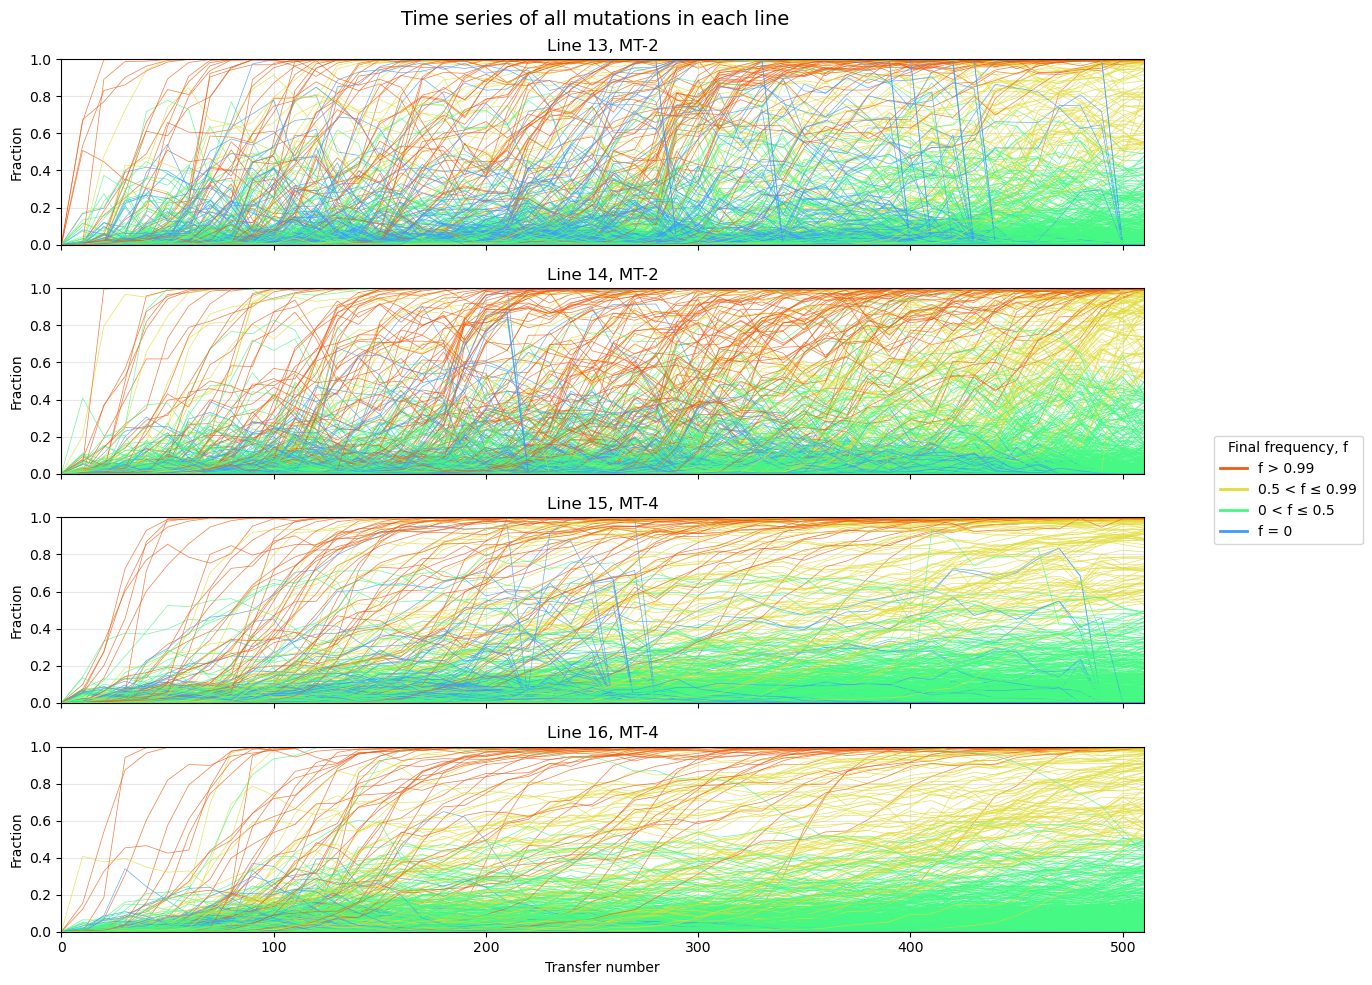

In [12]:
#Plot processed time series
fig, axes = plt.subplots(4,1,figsize=(12,10),sharex=True)


#Legend, final frequencies
cmap = plt.get_cmap('turbo')
color_options = [mcolors.to_hex(cmap(p)) for p in np.linspace(0.2, 0.8, 4)]
legend_handles = [
    Line2D([0], [0], color=color_options[3], lw=2, label="f > 0.99"),
    Line2D([0], [0], color=color_options[2], lw=2, label="0.5 < f ≤ 0.99"),
    Line2D([0], [0], color=color_options[1], lw=2, label="0 < f ≤ 0.5"),
    Line2D([0], [0], color=color_options[0], lw=2, label="f = 0"),    
]

# #Legend, mutation types
# cmap = plt.colormaps['Accent']
# color_options = [mcolors.to_hex(cmap(p)) for p in np.linspace(0, 0.7, 6)]
# legend_handles = [
#     Line2D([0], [0], color=color_options[0], lw=2, label="substitution"),
#     Line2D([0], [0], color=color_options[4], lw=2, label="insertion"),
#     Line2D([0], [0], color=color_options[5], lw=2, label="deletion"),  
# ]


#Plot time series
for i,ax in enumerate(axes):

    #Get line data
    data_line = data_time_series_no_drops[data_time_series_no_drops['line']==i+13]
    # data_line = data_line[data_line['type'] == 'substitution'] #'substitution', 'insertion', 'deletion'

    #Colours based on final frequencies
    last_passages = data_line[510]
    colours = np.where(last_passages == 0, color_options[0], color_options[1])
    colours = np.where(last_passages > 0.5, color_options[2], colours)
    colours = np.where(last_passages > 0.99, color_options[3], colours)

    # #Colours based on mutation type
    # mut_type = data_line['type']
    # colours = np.where(mut_type == 'substitution', color_options[0], color_options[5])
    # colours = np.where(mut_type == 'insertion', color_options[4], colours)

    #Plot 
    data_line[np.arange(0,511,10)].T.plot(ax=ax, color=colours, linewidth=0.5, legend=False, alpha=0.8) 

    #Format
    ax.grid(alpha=0.3)
    ax.set_xlabel('Transfer number')
    ax.set_ylabel('Fraction')
    ax.set_title(f'Line {i+13}, MT-{(np.floor(i/2)*2 +2).astype(int)}')
    ax.set_xlim(0,51)
    ax.set_ylim(0,1)

fig.legend(handles=legend_handles,loc="center left",bbox_to_anchor=(1.01, 0.5),title="Final frequency, f")
# fig.legend(handles=legend_handles,loc="center left",bbox_to_anchor=(1.01, 0.5),title="Mutation type")

fig.suptitle('Time series of all mutations in each line',fontsize=14)
plt.tight_layout(rect=[0, 0, 0.97, 1])
plt.savefig(fig_path + "/mutation_time_series_freqs.pdf", bbox_inches="tight")
# plt.savefig(fig_path + "/mutation_time_series_types.pdf", bbox_inches="tight")
plt.show()

Trajectories that drop associated with a drop in coverage, but not necessarily picked up as deletions in the sequencing data.

## Add mutation information

In [13]:
#Substitutions
data_time_series_no_drops = data_time_series_no_drops.merge(mutations_data, on=["pos", "new"], how="left")

#Indel types
data_time_series_no_drops.loc[data_time_series_no_drops['type']=='insertion','muttype'] = 'Insertion'
data_time_series_no_drops.loc[data_time_series_no_drops['type']=='insertion','details'] = '-'
data_time_series_no_drops.loc[data_time_series_no_drops['type']=='deletion','muttype'] = 'Deletion'
data_time_series_no_drops.loc[data_time_series_no_drops['type']=='deletion','details'] = '-'

#Indel genes
for i,row in gene_positions.iterrows():
    data_time_series_no_drops.loc[data_time_series_no_drops['gene'].isna() & (data_time_series_no_drops['pos'] >= row.start) & (data_time_series_no_drops['pos'] < row.end),'gene'] = row.genename
data_time_series_no_drops.loc[data_time_series_no_drops['gene'].isna(),'gene'] = '-'


In [14]:
#Reorder columns
columns = ['pos','new','line','type','gene','muttype','details','Max frequency','Length','Mean pop size']
data_time_series_no_drops = data_time_series_no_drops[np.concat((columns,np.arange(0,511,10)),dtype='object')]

## Add consensus alleles

In [15]:
consensus_rows = []

for line in [13,14,15,16]:
    #Add in consensus allele for substitutions
    for pos in data_time_series_no_drops[(data_time_series_no_drops['line']==line) & (data_time_series_no_drops['type']=='substitution')]['pos'].unique():
        data_line_pos = data_time_series_no_drops[(data_time_series_no_drops['line']==line) & (data_time_series_no_drops['type']=='substitution') & (data_time_series_no_drops['pos']==pos)]
        consensus_row = data_line_pos.iloc[0].copy()
        consensus_row['new'] = consensus[pos]
        consensus_row['details'] = 'consensus'
        consensus_row['Max frequency'] = 1
        consensus_row['Length'] = 51
        consensus_row.loc[np.arange(0,511,10)] = 1 - data_line_pos.loc[:,np.arange(0,511,10)].sum()
        consensus_rows.append(consensus_row.to_frame().T)

    #Add in consensus allele for insertions
    consensus_row = data_time_series_no_drops[(data_time_series_no_drops['line']==line) & (data_time_series_no_drops['type']=='insertion')].copy()
    consensus_row['new'] = '-' 
    consensus_row['details'] = 'consensus'
    consensus_row['Max frequency'] = 1
    consensus_row['Length'] = 51
    consensus_row.loc[:,np.arange(0,511,10)] = 1 - consensus_row.loc[:,np.arange(0,511,10)]
    consensus_rows.append(consensus_row)

    #Add in consensus allele for deletions
    consensus_row = data_time_series_no_drops[(data_time_series_no_drops['line']==line) & (data_time_series_no_drops['type']=='deletion')].copy()
    consensus_row['new'] = 'A' #Place holder for deleted sequence
    consensus_row['details'] = 'consensus'
    consensus_row['Max frequency'] = 1
    consensus_row['Length'] = 51
    consensus_row.loc[:,np.arange(0,511,10)] = 1 - consensus_row.loc[:,np.arange(0,511,10)]
    consensus_rows.append(consensus_row)


data_time_series_no_drops = pd.concat([data_time_series_no_drops,pd.concat(consensus_rows)])
data_time_series_no_drops = data_time_series_no_drops.sort_values(by=['pos','line','new']).reset_index(drop=True)

In [16]:
data_time_series_no_drops

,pos,new,line,type,gene,muttype,details,Max frequency,Length,Mean pop size,...,420,430,440,450,460,470,480,490,500,510
0,470,C,15,substitution,-,Non-coding,consensus,1,51,1778.4375,...,0.975153,0.936499,0.921283,0.913479,0.916375,0.887857,1.0,1.0,1.0,1.0
1,470,T,15,substitution,-,Non-coding,-,0.112143,16,1778.4375,...,0.024847,0.063501,0.078717,0.086521,0.083625,0.112143,0.0,0.0,0.0,0.0
2,470,C,16,substitution,-,Non-coding,consensus,1,51,1340.428571,...,1.0,0.934416,0.929472,0.924528,0.909091,0.911884,0.880711,1.0,1.0,1.0
3,470,T,16,substitution,-,Non-coding,-,0.119289,14,1340.428571,...,0.0,0.065584,0.070528,0.075472,0.090909,0.088116,0.119289,0.0,0.0,0.0
4,476,A,14,substitution,-,Non-coding,-,0.544809,14,2068.5,...,0.339856,0.526323,0.544809,0.322887,0.409858,0.496829,0.527148,0.44658,0.366013,0.396172
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8070,9578,G,16,substitution,-,Non-coding,-,0.075847,27,2606.222222,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.001009
8071,9582,A,14,substitution,-,Non-coding,consensus,1,51,2159.227273,...,0.930794,0.888166,0.988015,0.990677,0.994773,0.998868,1.0,1.0,1.0,1.0
8072,9582,G,14,substitution,-,Non-coding,-,0.121127,22,2159.227273,...,0.069206,0.111834,0.011985,0.009323,0.005227,0.001132,0.0,0.0,0.0,0.0
8073,9595,-,14,insertion,-,Insertion,consensus,1,51,2110.892857,...,0.998458,1.0,0.999492,0.99942,1.0,0.998381,0.996697,0.995012,0.998955,0.998955


## Save data

In [17]:
#Save mutations as a pickle file
data_time_series_no_drops.to_pickle(out_path + f'/mutation_time_series.pkl')